In [11]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

from sir_graph.dynamics import run_ensemble, simulate
from sir_graph.geometric import expected_mean_degree, random_geometric
from sir_graph.parameters import NodeParams
from sir_graph.states import State, choose_seeds

from ipywidgets import IntSlider, interact


N_NODES, RADIUS = 1000, 0.0723
P, Q = 0.7, 1.0
N_SEEDS = 2
rng = np.random.default_rng(22)

In [12]:
import pandas as pd
import numpy as np

N_NODES = 1000
DATA_SEED = 22

people = pd.read_csv("../data/synthetic_data.csv")

people = (
    people
    .sample(n=N_NODES, random_state=DATA_SEED)
    .reset_index(drop=True)
)

people.insert(
    0,
    "node_id",
    np.arange(N_NODES, dtype=np.int64)
)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate
0,0,35220,62,Female,Student,0,0,0,0.3329
1,1,29487,71,Female,Office-based,0,0,0,0.3428
2,2,38566,40,Male,Agriculture,1,1,1,0.3998
3,3,20529,70,Male,Office-based,1,1,0,0.4563
4,4,30182,54,Male,Healthcare,0,0,0,0.3793


edges: 7723
mean degree: 15.45 (theory 15.41)


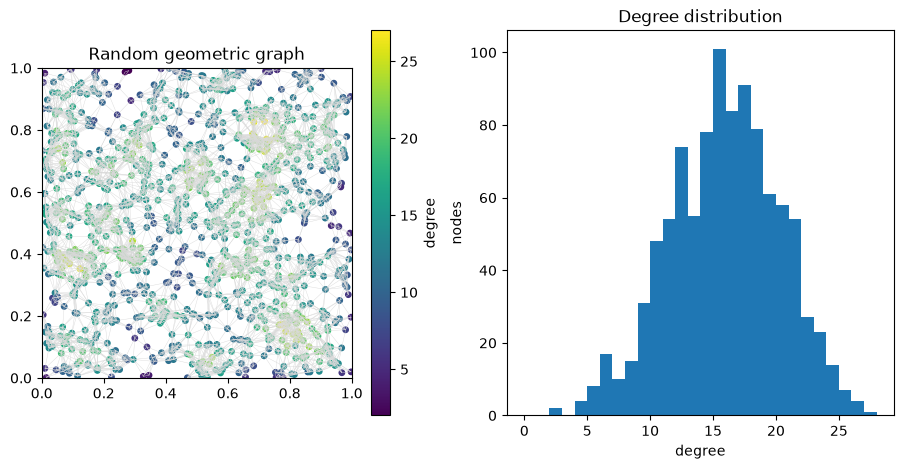

In [13]:
graph, pos = random_geometric(N_NODES, RADIUS, rng=rng)
degrees = np.diff(graph.indptr)

print(f"edges: {graph.n_edges}")
print(f"mean degree: {degrees.mean():.2f} (theory {expected_mean_degree(N_NODES, RADIUS):.2f})")

def draw_edges(ax, graph, pos):
    src = np.repeat(np.arange(graph.n_nodes), np.diff(graph.indptr))
    keep = src < graph.indices
    segs = np.stack([pos[src[keep]], pos[graph.indices[keep]]], axis=1)
    ax.add_collection(LineCollection(segs, colors="0.85", linewidths=0.3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
draw_edges(ax1, graph, pos)
sc = ax1.scatter(*pos.T, c=degrees, s=15, cmap="viridis")
fig.colorbar(sc, ax=ax1, label="degree")
ax1.set(aspect="equal", xlim=(0, 1), ylim=(0, 1), title="Random geometric graph")
ax2.hist(degrees, bins=range(degrees.max() + 2))
ax2.set(xlabel="degree", ylabel="nodes", title="Degree distribution")
plt.show()

final size: 1000/1000 after 14 steps


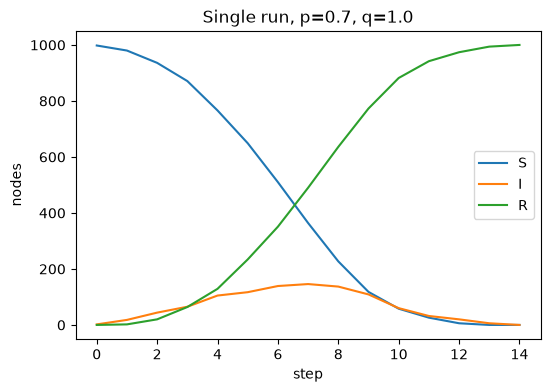

In [14]:
params = NodeParams.homogeneous(N_NODES, recovery=Q)
seeds = choose_seeds(N_NODES, N_SEEDS, rng=rng)
result = simulate(graph, seeds, P, params, rng=rng)

print(f"final size: {result.final_size}/{N_NODES} after {result.n_steps} steps")

fig, ax = plt.subplots(figsize=(6, 4))
for s in State:
    ax.plot(result.counts[:, s], label=s.name)
ax.set(xlabel="step", ylabel="nodes", title=f"Single run, p={P}, q={Q}")
ax.legend()
plt.show()

In [15]:
def state_at(result, t):
    """Reconstruct the S/I/R state of every node at time t."""
    inf_t, rec_t = result.infection_time, result.recovery_time
    state = np.full(result.n_nodes, State.S, dtype=np.int8)
    infected = (inf_t >= 0) & (inf_t <= t)
    state[infected] = State.I
    state[(rec_t >= 0) & (rec_t <= t)] = State.R
    return state

In [16]:

COLORS = np.array(["tab:blue", "tab:red", "tab:green"])   # S, I, R

def plot_at(t):
    state = state_at(result, t)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

    draw_edges(ax1, graph, pos)
    ax1.scatter(*pos.T, c=COLORS[state], s=10)
    ax1.scatter(*pos[result.seeds].T, marker=".", c="orange", s=120)
    ax1.set(aspect="equal", xlim=(0, 1), ylim=(0, 1), title=f"t = {t}")

    for s in State:
        ax2.plot(result.counts[:, s], color=COLORS[s], label=s.name)
    ax2.axvline(t, color="black", linestyle="--")
    ax2.set(xlabel="step", ylabel="nodes")
    ax2.legend()
    plt.show()

interact(plot_at, t=IntSlider(min=0, max=result.n_steps, step=1, value=0));

interactive(children=(IntSlider(value=0, description='t', max=14), Output()), _dom_classes=('widget-interact',…

In [17]:
from sir_graph.attributes import NodeAttributes

attributes = NodeAttributes(
    person_id=people["person_id"].to_numpy(dtype=np.int64),
    age=people["age"].to_numpy(dtype=np.int64),
    sex=people["sex"].to_numpy(dtype=str),
    occupation=people["occupation"].to_numpy(dtype=str),
    smoking=people["smoking"].to_numpy(dtype=bool),
    alcohol=people["alcohol"].to_numpy(dtype=bool),
    obesity=people["obesity"].to_numpy(dtype=bool),
)

infection_rate = people["infection_rate"].to_numpy(dtype=np.float64)

In [18]:
i = 17

print("Graph node:", i)
print("Person ID:", attributes.person_id[i])
print("Age:", attributes.age[i])
print("Sex:", attributes.sex[i])
print("Occupation:", attributes.occupation[i])
print("Smoking:", attributes.smoking[i])
print("Alcohol:", attributes.alcohol[i])
print("Obesity:", attributes.obesity[i])
print("Infection rate:", infection_rate[i])

Graph node: 17
Person ID: 3246
Age: 46
Sex: Male
Occupation: Agriculture
Smoking: False
Alcohol: False
Obesity: False
Infection rate: 0.2733


In [19]:
print("People:", len(people))
print("Attributes:", attributes.n_nodes)
print("Infection rates:", len(infection_rate))
print("Graph nodes:", graph.n_nodes)

assert len(people) == N_NODES
assert attributes.n_nodes == N_NODES
assert len(infection_rate) == N_NODES
assert graph.n_nodes == N_NODES

People: 1000
Attributes: 1000
Infection rates: 1000
Graph nodes: 1000


In [20]:
print("Nodes:", graph.n_nodes)
print("Edges:", graph.n_edges)
print("Mean degree:", graph.degree().mean())

Nodes: 1000
Edges: 7723
Mean degree: 15.446


In [21]:
from sir_graph.parameters import NodeParams

RECOVERY_PROB = 0.4

params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(N_NODES),
    recovery=np.full(N_NODES, RECOVERY_PROB),
)

In [22]:
from sir_graph.dynamics import simulate

result = simulate(
    graph,
    seeds=[0],
    p=1.0,
    params=params,
    rng=22,
)

print("Final infected:", result.final_size)
print("Steps:", result.n_steps)

Final infected: 998
Steps: 30


In [23]:
results_df = people.copy()

results_df["infected"] = result.ever_infected
results_df["infection_time"] = result.infection_time
results_df["recovery_time"] = result.recovery_time
results_df["secondary_infections"] = result.offspring

results_df.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,infected,infection_time,recovery_time,secondary_infections
0,0,35220,62,Female,Student,0,0,0,0.3329,True,0,1,7
1,1,29487,71,Female,Office-based,0,0,0,0.3428,True,12,14,2
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,True,18,22,0
3,3,20529,70,Male,Office-based,1,1,0,0.4563,True,17,21,0
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,True,11,12,0


In [24]:
results_df[~results_df["infected"]]

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,infected,infection_time,recovery_time,secondary_infections
697,697,38830,34,Male,Office-based,0,0,0,0.2281,False,-1,-1,0
903,903,12923,73,Male,Agriculture,0,0,0,0.2996,False,-1,-1,0


In [25]:
results_df["infection_time"].describe()

count    1000.000000
mean       10.951000
std         4.479807
min        -1.000000
25%         7.000000
50%        11.000000
75%        14.000000
max        21.000000
Name: infection_time, dtype: float64

In [26]:
results_df["secondary_infections"].describe()

count    1000.000000
mean        0.997000
std         1.315569
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         7.000000
Name: secondary_infections, dtype: float64

In [27]:
from sir_graph.dynamics import run_ensemble

N_RUNS = 100
N_SEEDS = 1

runs = run_ensemble(
    graph,
    n_runs=N_RUNS,
    n_seeds=N_SEEDS,
    p=1.0,
    params=params,
    rng=22,
)

print("Number of runs:", len(runs))

Number of runs: 100


In [28]:
infected_by_spread = np.stack([
    r.infection_time > 0
    for r in runs
])

infection_times = np.stack([
    r.infection_time
    for r in runs
])

offspring = np.stack([
    r.offspring
    for r in runs
])

In [29]:
infection_probability = infected_by_spread.mean(axis=0)

In [30]:
valid = infection_times > 0

infection_time_sum = np.where(
    valid,
    infection_times,
    0
).sum(axis=0)

infection_count = valid.sum(axis=0)

mean_infection_time = np.divide(
    infection_time_sum,
    infection_count,
    out=np.full(N_NODES, np.nan),
    where=infection_count > 0,
)

In [31]:
mean_secondary_infections = offspring.mean(axis=0)

In [32]:
emm_df = people.copy()

emm_df["infection_probability"] = infection_probability
emm_df["mean_infection_time"] = mean_infection_time
emm_df["mean_secondary_infections"] = mean_secondary_infections

emm_df.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,infection_probability,mean_infection_time,mean_secondary_infections
0,0,35220,62,Female,Student,0,0,0,0.3329,1.0,11.46,1.04
1,1,29487,71,Female,Office-based,0,0,0,0.3428,1.0,12.27,1.09
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,1.0,13.54,0.46
3,3,20529,70,Male,Office-based,1,1,0,0.4563,1.0,12.72,1.23
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,1.0,12.37,0.99


In [33]:
emm_df[
    [
        "infection_probability",
        "mean_infection_time",
        "mean_secondary_infections",
    ]
].describe()

,infection_probability,mean_infection_time,mean_secondary_infections
count,1000.000000,1000.000000,1000.000000
mean,0.996710,12.095954,0.996710
std,0.023195,1.751203,0.440423
min,0.510000,9.120000,0.050000
25%,1.000000,10.677500,0.700000
50%,1.000000,11.915000,0.980000
75%,1.000000,13.350000,1.300000
max,1.000000,17.156863,2.720000


In [34]:
P_VALUES = [0.20, 0.225, 0.25, 0.275, 0.30]

comparison = []

for p_value in P_VALUES:
    test_runs = run_ensemble(
        graph,
        n_runs=100,
        n_seeds=5,
        p=p_value,
        params=params,
        rng=22,
    )

    final_sizes = np.array([r.final_size for r in test_runs])

    comparison.append({
        "p": p_value,
        "mean_final_size": final_sizes.mean(),
        "mean_fraction_infected": final_sizes.mean() / N_NODES,
        "min_final_size": final_sizes.min(),
        "max_final_size": final_sizes.max(),
    })

pd.DataFrame(comparison)

,p,mean_final_size,mean_fraction_infected,min_final_size,max_final_size
0,0.200,676.08,0.67608,74,836
1,0.225,780.72,0.78072,248,880
2,0.250,845.03,0.84503,635,903
3,0.275,893.43,0.89343,781,946
4,0.300,916.92,0.91692,841,956


In [35]:
from sir_graph.dynamics import run_ensemble
import numpy as np

N_RUNS = 500
N_SEEDS = 5
P = 0.20

runs = run_ensemble(
    graph,
    n_runs=N_RUNS,
    n_seeds=N_SEEDS,
    p=P,
    params=params,
    rng=22,
)

# Was each person infected through spread?
infected_by_spread = np.stack([
    r.infection_time > 0
    for r in runs
])

# Was each person chosen as an initial seed?
was_seed = np.stack([
    np.isin(np.arange(N_NODES), r.seeds)
    for r in runs
])

# Only runs where that person was NOT an artificial initial seed
eligible_runs = ~was_seed

infection_probability = (
    infected_by_spread.sum(axis=0)
    / eligible_runs.sum(axis=0)
)

# Infection times
infection_times = np.stack([
    r.infection_time
    for r in runs
])

valid_infections = infection_times > 0

mean_infection_time = np.divide(
    np.where(valid_infections, infection_times, 0).sum(axis=0),
    valid_infections.sum(axis=0),
    out=np.full(N_NODES, np.nan),
    where=valid_infections.sum(axis=0) > 0,
)

# Secondary infections
offspring = np.stack([
    r.offspring
    for r in runs
])

mean_secondary_infections = offspring.mean(axis=0)

In [36]:
emm_df = people.copy()

emm_df["infection_probability"] = infection_probability
emm_df["mean_infection_time"] = mean_infection_time
emm_df["mean_secondary_infections"] = mean_secondary_infections

emm_df.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,infection_probability,mean_infection_time,mean_secondary_infections
0,0,35220,62,Female,Student,0,0,0,0.3329,0.617234,26.217532,0.722
1,1,29487,71,Female,Office-based,0,0,0,0.3428,0.738431,21.686649,0.696
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,0.469880,28.213675,0.298
3,3,20529,70,Male,Office-based,1,1,0,0.4563,0.861167,21.028037,0.910
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,0.813253,21.434568,0.796


In [37]:
emm_df[
    [
        "infection_probability",
        "mean_infection_time",
        "mean_secondary_infections"
    ]
].describe()

,infection_probability,mean_infection_time,mean_secondary_infections
count,1000.000000,1000.000000,1000.000000
mean,0.670244,23.116871,0.666872
std,0.190006,3.600945,0.297207
min,0.030000,15.987315,0.002000
25%,0.544000,20.272993,0.448000
50%,0.713279,22.540399,0.676000
75%,0.827655,26.172017,0.872000
max,0.953908,33.200000,1.492000


In [38]:
emm_df["degree"] = graph.degree()

In [39]:
emm_df[
    [
        "infection_rate",
        "degree",
        "infection_probability",
        "mean_infection_time",
        "mean_secondary_infections",
    ]
].corr()

,infection_rate,degree,infection_probability,mean_infection_time,mean_secondary_infections
infection_rate,1.000000,-0.027018,0.262518,-0.116890,0.268694
degree,-0.027018,1.000000,0.770043,-0.577167,0.887024
infection_probability,0.262518,0.770043,1.000000,-0.856323,0.875758
mean_infection_time,-0.116890,-0.577167,-0.856323,1.000000,-0.713865
mean_secondary_infections,0.268694,0.887024,0.875758,-0.713865,1.000000


In [40]:
emm_df.groupby("sex")[
    "infection_probability"
].agg(["count", "mean", "std"])

,count,mean,std
sex,,,
Female,389,0.684821,0.183881
Male,611,0.660964,0.193381


In [41]:
emm_df.groupby("occupation")[
    "infection_probability"
].agg(["count", "mean", "std"])

,count,mean,std
occupation,,,
Agriculture,109,0.658604,0.196770
Healthcare,182,0.723218,0.168781
Office-based,165,0.669721,0.202428
Other,153,0.635672,0.184179
Sales and services,145,0.674358,0.179461
Student,246,0.655638,0.196407


In [42]:
for col in ["smoking", "alcohol", "obesity"]:
    print("\n", col)
    print(
        emm_df.groupby(col)["infection_probability"]
        .agg(["count", "mean", "std"])
    )


 smoking
         count      mean       std
smoking                           
0          401  0.642353  0.195583
1          599  0.688916  0.183993

 alcohol
         count      mean       std
alcohol                           
0          700  0.657038  0.188583
1          300  0.701058  0.190056

 obesity
         count      mean       std
obesity                           
0          945  0.667519  0.191483
1           55  0.717070  0.156698


In [43]:
emm_df["age_group"] = pd.cut(
    emm_df["age"],
    bins=[0, 18, 30, 45, 60, 75, 120],
    labels=[
        "0-18",
        "19-30",
        "31-45",
        "46-60",
        "61-75",
        "76+",
    ],
)

emm_df.groupby("age_group", observed=True)[
    "infection_probability"
].agg(["count", "mean", "std"])

,count,mean,std
age_group,,,
0-18,279,0.657742,0.183250
19-30,160,0.619292,0.200202
31-45,200,0.656924,0.193370
46-60,183,0.710415,0.179304
61-75,178,0.709307,0.184180


In [44]:
from sir_graph.geometric import random_geometric

N_NODES = 1000
RADIUS = 0.0723
NETWORK_SEED = 22

baseline_graph, positions = random_geometric(
    N_NODES,
    RADIUS,
    rng=NETWORK_SEED,
)

print("Nodes:", baseline_graph.n_nodes)
print("Edges:", baseline_graph.n_edges)
print("Mean degree:", baseline_graph.degree().mean())

Nodes: 1000
Edges: 7723
Mean degree: 15.446


In [45]:
original_degree_sequence = baseline_graph.degree().copy()

print("Mean degree:", original_degree_sequence.mean())
print("Min degree:", original_degree_sequence.min())
print("Max degree:", original_degree_sequence.max())

Mean degree: 15.446
Min degree: 2
Max degree: 27


In [46]:
from sir_graph.havel_hakimi import (
    havel_hakimi,
    randomize_degree_preserving,
)

hh_graph = havel_hakimi(original_degree_sequence)

In [47]:
import numpy as np
print("HH nodes:", hh_graph.n_nodes)
print("HH edges:", hh_graph.n_edges)
print("HH mean degree:", hh_graph.degree().mean())

print(
    "Degrees identical:",
    np.array_equal(
        hh_graph.degree(),
        original_degree_sequence
    )
)

HH nodes: 1000
HH edges: 7723
HH mean degree: 15.446
Degrees identical: True


In [48]:
N_SWAPS = 10 * hh_graph.n_edges

random_graph = randomize_degree_preserving(
    hh_graph,
    n_swaps=N_SWAPS,
    rng=22,
)

In [49]:
print("Randomized nodes:", random_graph.n_nodes)
print("Randomized edges:", random_graph.n_edges)
print("Randomized mean degree:", random_graph.degree().mean())

print(
    "Degrees still identical:",
    np.array_equal(
        random_graph.degree(),
        original_degree_sequence
    )
)

Randomized nodes: 1000
Randomized edges: 7723
Randomized mean degree: 15.446
Degrees still identical: True


In [50]:
graph = random_graph

In [51]:
planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy()

print("Planted subgroup size:", planted_mask.sum())
print("Fraction of population:", planted_mask.mean())

Planted subgroup size: 117
Fraction of population: 0.117


In [52]:
from sir_graph.parameters import NodeParams

RECOVERY_PROB = 0.4

base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(N_NODES),
    recovery=np.full(N_NODES, RECOVERY_PROB),
)

In [53]:
PLANTED_MULTIPLIER = 1.75

planted_params = base_params.scaled(
    planted_mask,
    infectiousness=PLANTED_MULTIPLIER,
)

In [54]:
print(
    "Normal infectiousness:",
    np.unique(planted_params.infectiousness[~planted_mask])
)

print(
    "Planted infectiousness:",
    np.unique(planted_params.infectiousness[planted_mask])
)

Normal infectiousness: [1.]
Planted infectiousness: [1.75]


In [55]:
print(
    "Susceptibility unchanged:",
    np.array_equal(
        base_params.susceptibility,
        planted_params.susceptibility
    )
)

Susceptibility unchanged: True


In [56]:
from sir_graph.dynamics import run_ensemble

P_VALUES = [0.15, 0.175, 0.20, 0.225, 0.25]

comparison = []

for p_value in P_VALUES:
    test_runs = run_ensemble(
        graph,
        n_runs=100,
        n_seeds=5,
        p=p_value,
        params=planted_params,
        rng=24,
    )

    final_sizes = np.array([
        r.final_size
        for r in test_runs
    ])

    comparison.append({
        "p": p_value,
        "mean_final_size": final_sizes.mean(),
        "mean_fraction_infected": final_sizes.mean() / N_NODES,
        "min_final_size": final_sizes.min(),
        "max_final_size": final_sizes.max(),
    })

pd.DataFrame(comparison)

,p,mean_final_size,mean_fraction_infected,min_final_size,max_final_size
0,0.150,754.74,0.75474,686,801
1,0.175,823.74,0.82374,768,871
2,0.200,869.29,0.86929,830,900
3,0.225,892.27,0.89227,10,930
4,0.250,926.12,0.92612,893,955


In [57]:
P_VALUES = [0.08, 0.10, 0.12, 0.14, 0.15]

comparison = []

for p_value in P_VALUES:
    for condition, current_params in [
        ("control", base_params),
        ("planted", planted_params),
    ]:
        test_runs = run_ensemble(
            graph,
            n_runs=100,
            n_seeds=5,
            p=p_value,
            params=current_params,
            rng=24,
        )

        final_sizes = np.array([
            r.final_size
            for r in test_runs
        ])

        comparison.append({
            "condition": condition,
            "p": p_value,
            "mean_final_size": final_sizes.mean(),
            "mean_fraction_infected": final_sizes.mean() / N_NODES,
            "median_final_size": np.median(final_sizes),
            "min_final_size": final_sizes.min(),
            "max_final_size": final_sizes.max(),
        })

comparison_df = pd.DataFrame(comparison)

comparison_df

,condition,p,mean_final_size,mean_fraction_infected,median_final_size,min_final_size,max_final_size
0,control,0.08,59.78,0.05978,39.0,5,269
1,planted,0.08,105.85,0.10585,51.5,5,333
2,control,0.10,247.74,0.24774,296.5,5,511
3,planted,0.10,386.95,0.38695,440.5,8,558
4,control,0.12,479.26,0.47926,533.5,6,644
5,planted,0.12,600.92,0.60092,615.5,8,708
6,control,0.14,634.26,0.63426,657.5,8,728
7,planted,0.14,713.46,0.71346,715.5,623,768
8,control,0.15,696.70,0.69670,700.0,14,766
9,planted,0.15,754.74,0.75474,761.5,686,801


In [58]:
from sir_graph.dynamics import simulate

P = 0.12
N_RUNS = 500
N_SEEDS = 5

# Separate reproducible random streams
seed_rng = np.random.default_rng(1001)
epidemic_rng = np.random.default_rng(1002)

# Same initial infected people for control and planted condition
seed_sets = [
    np.sort(
        seed_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False
        )
    )
    for _ in range(N_RUNS)
]

# Same simulation seed for corresponding control/planted runs
run_rng_seeds = epidemic_rng.integers(
    0,
    2**32 - 1,
    size=N_RUNS,
    dtype=np.uint32,
)

In [59]:
def run_fixed_ensemble(params):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds
        )
    ]

In [60]:
control_runs = run_fixed_ensemble(base_params)
planted_runs = run_fixed_ensemble(planted_params)

print("Control runs:", len(control_runs))
print("Planted runs:", len(planted_runs))

Control runs: 500
Planted runs: 500


In [61]:
control_final_sizes = np.array([
    r.final_size for r in control_runs
])

planted_final_sizes = np.array([
    r.final_size for r in planted_runs
])

print(
    "Control mean final size:",
    control_final_sizes.mean()
)

print(
    "Planted mean final size:",
    planted_final_sizes.mean()
)

Control mean final size: 496.334
Planted mean final size: 581.396


In [62]:
def per_node_spreading_metrics(runs):
    infection_times = np.stack([
        r.infection_time
        for r in runs
    ])

    offspring = np.stack([
        r.offspring
        for r in runs
    ])

    # > 0 means naturally infected;
    # time 0 means artificially selected as seed
    naturally_infected = infection_times > 0

    n_natural_infections = naturally_infected.sum(axis=0)

    total_secondary = np.where(
        naturally_infected,
        offspring,
        0
    ).sum(axis=0)

    mean_secondary_when_infected = np.divide(
        total_secondary,
        n_natural_infections,
        out=np.full(N_NODES, np.nan),
        where=n_natural_infections > 0,
    )

    return (
        n_natural_infections,
        mean_secondary_when_infected
    )

In [63]:
(
    control_infection_count,
    control_spread
) = per_node_spreading_metrics(control_runs)

(
    planted_infection_count,
    planted_spread
) = per_node_spreading_metrics(planted_runs)

In [64]:
analysis_df = people.copy()

analysis_df["degree"] = graph.degree()

analysis_df["control_infection_count"] = (
    control_infection_count
)

analysis_df["control_mean_secondary"] = (
    control_spread
)

analysis_df["planted_infection_count"] = (
    planted_infection_count
)

analysis_df["planted_mean_secondary"] = (
    planted_spread
)

# Ground truth — ONLY for evaluation later
analysis_df["is_planted"] = planted_mask

In [65]:
analysis_df.groupby("is_planted")[
    [
        "degree",
        "control_mean_secondary",
        "planted_mean_secondary",
    ]
].mean()

,degree,control_mean_secondary,planted_mean_secondary
is_planted,,,
False,15.497169,0.928806,0.856661
True,15.059829,0.912526,1.413209


In [66]:
x_control = analysis_df["degree"].to_numpy()
y_control = analysis_df["control_mean_secondary"].to_numpy()

valid = np.isfinite(y_control)

slope, intercept = np.polyfit(
    x_control[valid],
    y_control[valid],
    1
)

print("Intercept:", intercept)
print("Slope:", slope)

Intercept: -0.1079548708373312
Slope: 0.06699831130236064


In [67]:
analysis_df["expected_from_degree"] = (
    intercept
    + slope * analysis_df["degree"]
)

In [68]:
analysis_df["spread_residual"] = (
    analysis_df["planted_mean_secondary"]
    - analysis_df["expected_from_degree"]
)

In [69]:
analysis_df.groupby("is_planted").agg(
    count=("node_id", "count"),
    mean_degree=("degree", "mean"),
    mean_actual_spread=("planted_mean_secondary", "mean"),
    mean_expected_spread=("expected_from_degree", "mean"),
    mean_residual=("spread_residual", "mean"),
)

,count,mean_degree,mean_actual_spread,mean_expected_spread,mean_residual
is_planted,,,,,
False,883,15.497169,0.856661,0.930329,-0.073668
True,117,15.059829,1.413209,0.901028,0.512180


In [70]:
columns = [
    "node_id",
    "age",
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
    "degree",
    "planted_mean_secondary",
    "expected_from_degree",
    "spread_residual",
    "is_planted",
]

analysis_df.sort_values(
    "spread_residual",
    ascending=False
)[columns].head(20)

,node_id,age,sex,occupation,smoking,alcohol,obesity,degree,planted_mean_secondary,expected_from_degree,spread_residual,is_planted
849,849,72,Female,Healthcare,1,0,0,26,2.730337,1.634001,1.096336,True
352,352,70,Female,Student,1,1,0,21,2.332547,1.299010,1.033538,True
79,79,61,Female,Student,1,0,0,23,2.408867,1.433006,0.975861,True
46,46,63,Male,Healthcare,1,0,0,21,2.264781,1.299010,0.965772,True
554,554,72,Male,Office-based,1,0,0,24,2.432642,1.500005,0.932638,True
624,624,63,Male,Office-based,1,0,0,22,2.283163,1.366008,0.917155,True
402,402,60,Male,Office-based,1,1,0,21,2.213615,1.299010,0.914605,True
63,63,67,Female,Student,1,0,0,23,2.325416,1.433006,0.892409,True
935,935,63,Female,Healthcare,1,0,0,21,2.184080,1.299010,0.885070,True
515,515,64,Male,Healthcare,1,0,0,20,2.107417,1.232011,0.875406,True


In [71]:
x = analysis_df["degree"].to_numpy()
y = analysis_df["planted_mean_secondary"].to_numpy()

valid = np.isfinite(y)

emm_slope, emm_intercept = np.polyfit(
    x[valid],
    y[valid],
    1,
)

print("EMM intercept:", emm_intercept)
print("EMM slope:", emm_slope)

EMM intercept: -0.10939657071224125
EMM slope: 0.06675991329425023


In [72]:
analysis_df["emm_expected_spread"] = (
    emm_intercept
    + emm_slope * analysis_df["degree"]
)

analysis_df["emm_residual"] = (
    analysis_df["planted_mean_secondary"]
    - analysis_df["emm_expected_spread"]
)

In [73]:
analysis_df.groupby("is_planted").agg(
    count=("node_id", "count"),
    mean_degree=("degree", "mean"),
    mean_actual=("planted_mean_secondary", "mean"),
    mean_expected=("emm_expected_spread", "mean"),
    mean_residual=("emm_residual", "mean"),
)

,count,mean_degree,mean_actual,mean_expected,mean_residual
is_planted,,,,,
False,883,15.497169,0.856661,0.925193,-0.068532
True,117,15.059829,1.413209,0.895996,0.517212


In [74]:
def score_subgroup(mask, residuals, min_size=20):
    mask = np.asarray(mask, dtype=bool)

    n = len(mask)
    n_group = mask.sum()

    if n_group < min_size:
        return None

    if n_group > n - min_size:
        return None

    mean_group = residuals[mask].mean()
    mean_rest = residuals[~mask].mean()

    difference = mean_group - mean_rest

    quality = np.sqrt(n_group / n) * difference

    return {
        "size": int(n_group),
        "support": n_group / n,
        "mean_residual": mean_group,
        "rest_mean_residual": mean_rest,
        "difference": difference,
        "quality": quality,
    }

In [75]:
candidates = []

# Binary / categorical attributes
for col in [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]:
    for value in analysis_df[col].unique():
        candidates.append({
            "description": f"{col} == {value}",
            "attribute": col,
            "mask": (analysis_df[col] == value).to_numpy(),
        })

# Age thresholds
for threshold in range(20, 81, 5):
    candidates.append({
        "description": f"age >= {threshold}",
        "attribute": "age",
        "mask": (analysis_df["age"] >= threshold).to_numpy(),
    })

    candidates.append({
        "description": f"age < {threshold}",
        "attribute": "age",
        "mask": (analysis_df["age"] < threshold).to_numpy(),
    })

In [76]:
residuals = analysis_df["emm_residual"].to_numpy()

results = []

for candidate in candidates:
    score = score_subgroup(
        candidate["mask"],
        residuals,
    )

    if score is not None:
        results.append({
            "description": candidate["description"],
            **score,
        })

single_results = (
    pd.DataFrame(results)
    .sort_values("quality", ascending=False)
    .reset_index(drop=True)
)

single_results.head(15)

,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,age >= 60,192,0.192,0.293463,-0.069734,0.363196,0.159145
1,age >= 55,254,0.254,0.206918,-0.070452,0.277369,0.139790
2,age >= 50,316,0.316,0.154651,-0.071447,0.226098,0.127099
3,age >= 45,373,0.373,0.121538,-0.072302,0.193840,0.118385
4,age >= 40,430,0.430,0.100744,-0.076000,0.176743,0.115898
5,age >= 35,491,0.491,0.078873,-0.076083,0.154956,0.108580
6,age >= 65,117,0.117,0.278663,-0.036924,0.315587,0.107947
7,age >= 30,576,0.576,0.058260,-0.079145,0.137405,0.104283
8,smoking == 1,599,0.599,0.052342,-0.078186,0.130528,0.101022
9,age >= 25,639,0.639,0.045039,-0.079723,0.124762,0.099731


In [77]:
pair_results = []

for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):

        a = candidates[i]
        b = candidates[j]

        # Don't combine two conditions from the same attribute yet
        if a["attribute"] == b["attribute"]:
            continue

        mask = a["mask"] & b["mask"]

        score = score_subgroup(
            mask,
            residuals,
        )

        if score is not None:
            pair_results.append({
                "description": (
                    f'{a["description"]} AND '
                    f'{b["description"]}'
                ),
                **score,
            })

pair_results = (
    pd.DataFrame(pair_results)
    .sort_values("quality", ascending=False)
    .reset_index(drop=True)
)

pair_results.head(20)

,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,smoking == 1 AND age >= 60,117,0.117,0.517212,-0.068532,0.585744,0.200355
1,smoking == 1 AND age >= 55,151,0.151,0.388422,-0.069083,0.457505,0.177780
2,smoking == 1 AND age >= 50,185,0.185,0.312274,-0.070884,0.383159,0.164803
3,obesity == 0 AND age >= 60,183,0.183,0.292663,-0.065554,0.358216,0.153240
4,smoking == 1 AND age >= 45,218,0.218,0.254380,-0.070914,0.325295,0.151882
5,smoking == 1 AND age >= 40,256,0.256,0.212699,-0.073187,0.285886,0.144648
6,smoking == 1 AND age >= 65,70,0.070,0.498543,-0.037525,0.536068,0.141830
7,smoking == 1 AND age >= 35,296,0.296,0.176275,-0.074116,0.250391,0.136228
8,obesity == 0 AND age >= 55,241,0.241,0.207087,-0.065755,0.272842,0.133943
9,smoking == 1 AND age >= 30,344,0.344,0.143761,-0.075387,0.219148,0.128534


In [78]:
discovered_mask = (
    (analysis_df["age"] >= 60)
    & (analysis_df["smoking"] == 1)
).to_numpy()

true_mask = analysis_df["is_planted"].to_numpy()

intersection = np.sum(discovered_mask & true_mask)
union = np.sum(discovered_mask | true_mask)

jaccard = intersection / union

print("Jaccard:", jaccard)

Jaccard: 1.0


In [79]:
x = analysis_df["degree"].to_numpy()
y = analysis_df["control_mean_secondary"].to_numpy()

valid = np.isfinite(y)

control_slope, control_intercept = np.polyfit(
    x[valid],
    y[valid],
    1,
)

analysis_df["control_expected"] = (
    control_intercept
    + control_slope * analysis_df["degree"]
)

analysis_df["control_residual"] = (
    analysis_df["control_mean_secondary"]
    - analysis_df["control_expected"]
)

print("Control intercept:", control_intercept)
print("Control slope:", control_slope)

Control intercept: -0.1079548708373312
Control slope: 0.06699831130236064


In [80]:
control_residuals = analysis_df["control_residual"].to_numpy()

control_pair_results = []

for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):

        a = candidates[i]
        b = candidates[j]

        if a["attribute"] == b["attribute"]:
            continue

        mask = a["mask"] & b["mask"]

        score = score_subgroup(
            mask,
            control_residuals,
        )

        if score is not None:
            control_pair_results.append({
                "description": (
                    f'{a["description"]} AND '
                    f'{b["description"]}'
                ),
                **score,
            })

control_pair_results = (
    pd.DataFrame(control_pair_results)
    .sort_values("quality", ascending=False)
    .reset_index(drop=True)
)

control_pair_results.head(20)

,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,smoking == 1 AND age >= 25,377,0.377,0.014542,-0.008800,0.023341,0.014332
1,smoking == 1 AND age >= 30,344,0.344,0.015829,-0.008301,0.024130,0.014153
2,smoking == 1 AND age < 75,599,0.599,0.007101,-0.010607,0.017708,0.013706
3,smoking == 1 AND age < 80,599,0.599,0.007101,-0.010607,0.017708,0.013706
4,smoking == 1 AND age >= 20,417,0.417,0.012314,-0.008808,0.021122,0.013640
5,smoking == 1 AND age >= 40,256,0.256,0.019822,-0.006821,0.026643,0.013480
6,smoking == 1 AND age >= 35,296,0.296,0.016285,-0.006847,0.023131,0.012585
7,smoking == 1 AND age < 70,563,0.563,0.006884,-0.008869,0.015753,0.011820
8,alcohol == 1 AND age >= 20,213,0.213,0.019026,-0.005149,0.024175,0.011157
9,smoking == 1 AND age < 65,529,0.529,0.007069,-0.007940,0.015009,0.010916


In [81]:
target_description = "smoking == 1 AND age >= 60"

match = control_pair_results[
    control_pair_results["description"] == target_description
]

match

,description,size,support,mean_residual,rest_mean_residual,difference,quality
68,smoking == 1 AND age >= 60,117,0.117,0.011498,-0.001523,0.013021,0.004454


In [82]:
control_rank = (
    control_pair_results.index[
        control_pair_results["description"]
        == target_description
    ][0]
    + 1
)

print("Control rank of planted subgroup:", control_rank)

Control rank of planted subgroup: 69
